# Individuell uppgift – Hälsostudie, Del 1

Analys av data från en hälsostudie med 800 deltagare: beskrivande statistik, grafer, simulering, konfidensintervall, hypotesprövning och power.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

# Inställningar för diagram
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.constrained_layout.use": True,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=["royalblue", "darkorange", "seagreen"]),
})

### Inläsning och första granskning av data

Kontroll av datasetets storlek, datatyper, saknade värden, dubbletter och vilka värden de kategoriska variablerna har.

In [2]:
df = pd.read_csv("data/health_study_dataset.csv")

display(df.head())
df.info()
display(df.describe())

print("Antal dubbletter av id:", df["id"].duplicated().sum())
print("Antal dubbletter av rader (exklusive id):", df.drop(columns="id").duplicated().sum())

print("\nFördelning av kön:")
print(df["sex"].value_counts())
print("\nFördelning av rökare:")
print(df["smoker"].value_counts())
print("\nFördelning av sjukdom (0 = frisk, 1 = sjuk):")
print(df["disease"].value_counts())

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    object 
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    object 
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 56.4+ KB


,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


Antal dubbletter av id: 0
Antal dubbletter av rader (exklusive id): 0

Fördelning av kön:
sex
F    403
M    397
Name: count, dtype: int64

Fördelning av rökare:
smoker
No     587
Yes    213
Name: count, dtype: int64

Fördelning av sjukdom (0 = frisk, 1 = sjuk):
disease
0    753
1     47
Name: count, dtype: int64


800 deltagare och 9 kolumner. Inga saknade värden eller dubbletter. `sex` och `smoker` har två kategorier vardera, och `disease` är binär (0/1), vilket stämmer med uppgiftsbeskrivningen.

### Beskrivande statistik

Medelvärde, median, minimum och maximum för de numeriska variablerna.

In [3]:
num_col = ["age", "weight", "height", "systolic_bp", "cholesterol"]

descriptive_stats = df[num_col].agg(["mean", "median", "min", "max"]).T
descriptive_stats.columns = ["Medelvärde", "Median", "Min", "Max"]

display(descriptive_stats.round(2))

,Medelvärde,Median,Min,Max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


- Medelvärde och median ligger nära varandra för alla variabler, vilket tyder på ungefär symmetriska fördelningar.
- Lägsta vikten (33,7 kg) är mycket låg för en vuxen. Vikt används inte i analyserna i del 1, men värdena bör kontrolleras inför del 2.
- **Kolesterol:** Medelvärdet (ca 4,9 mmol/L) ligger nära typiska värden för totalkolesterol, så variabeln tolkas som totalkolesterol. Det är ett antagande. Ett önskvärt värde anges ofta som under ca 5 mmol/L (källa: https://www.1177.se/sjukdomar--besvar/hjarta-och-blodkarl/blodkarl/hoga-blodfetter/).
- **Blodtryck:** Medelvärdet för systoliskt blodtryck (ca 149 mmHg) är högt. Värden från 140 mmHg räknas vanligtvis som högt blodtryck (källa: https://www.1177.se/sjukdomar--besvar/hjarta-och-blodkarl/blodtryck/hogt-blodtryck/).

### Analysplan

| Beslut | Val |
|---|---|
| Population | Vuxna 18–90 år enligt datan. Urvalsmetoden är okänd, så resultaten kan inte generaliseras utan förbehåll |
| Studietyp | Observationsstudie: rökare jämförs med icke-rökare. Resultaten visar samband, inte orsakssamband |
| Primär variabel | `systolic_bp` (mmHg), kontinuerlig |
| Praktiskt betydelsefull skillnad | 5 mmHg, eftersom en sänkning på 5 mmHg anses kliniskt relevant (källa: https://pmc.ncbi.nlm.nih.gov/articles/PMC6513382/) |
| Signifikansnivå | α = 0,05 |
| Test | Ensidigt, eftersom hypotesen har en bestämd riktning |
| Stickprov | Fast: 800 deltagare (213 rökare, 587 icke-rökare) |
| Sekundära analyser | Konfidensintervall, andel sjuka per rökstatus. Kolesterol används endast beskrivande. Analyserna är utforskande |

### Grafer

Visualisering av blodtrycksfördelning, vikt per kön, andel rökare och andel sjuka per rökstatus.

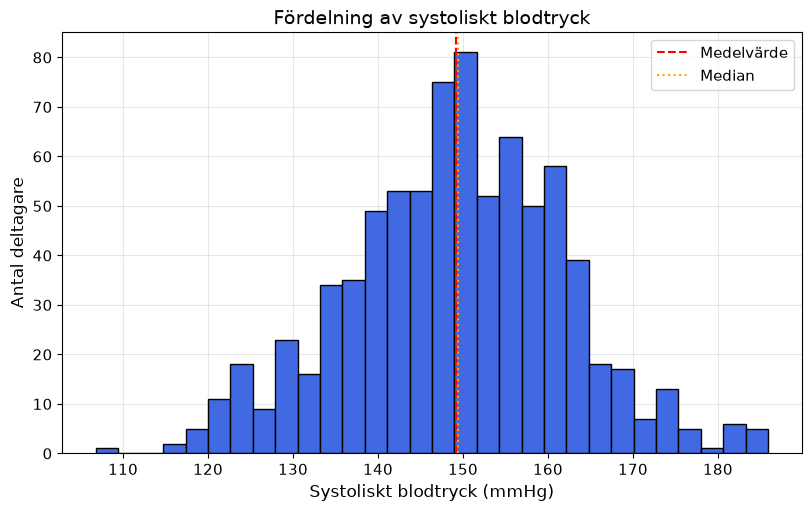

In [4]:
fig, ax = plt.subplots()

ax.hist(df["systolic_bp"], bins=30, edgecolor="black")
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Medelvärde")
ax.axvline(df["systolic_bp"].median(), color="orange", linestyle=":", label="Median")

ax.set_title("Fördelning av systoliskt blodtryck")
ax.set_xlabel("Systoliskt blodtryck (mmHg)")
ax.set_ylabel("Antal deltagare")
ax.legend()

plt.show()

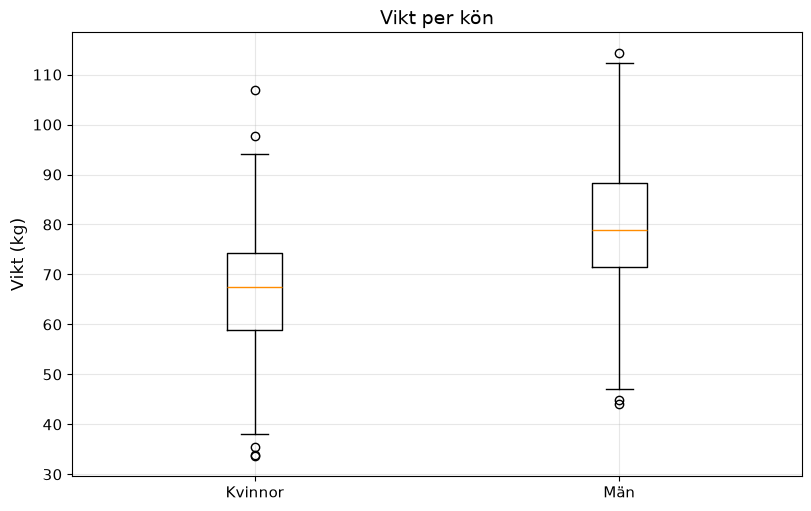

In [5]:
weight_female = df.loc[df["sex"] == "F", "weight"]
weight_male = df.loc[df["sex"] == "M", "weight"]

fig, ax = plt.subplots()

ax.boxplot([weight_female, weight_male])
ax.set_xticks([1, 2])
ax.set_xticklabels(["Kvinnor", "Män"])

ax.set_title("Vikt per kön")
ax.set_ylabel("Vikt (kg)")

plt.show()

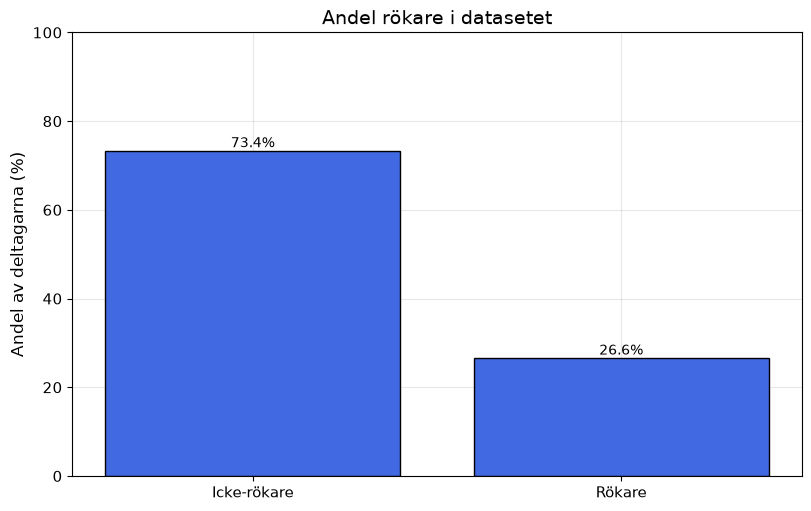

In [6]:
smoker_share = df["smoker"].value_counts(normalize=True) * 100
smoker_share = smoker_share.reindex(["No", "Yes"])

fig, ax = plt.subplots()

bars = ax.bar(["Icke-rökare", "Rökare"], smoker_share.values, edgecolor="black")
ax.bar_label(bars, fmt="%.1f%%")

ax.set_title("Andel rökare i datasetet")
ax.set_ylabel("Andel av deltagarna (%)")
ax.set_ylim(0, 100)

plt.show()

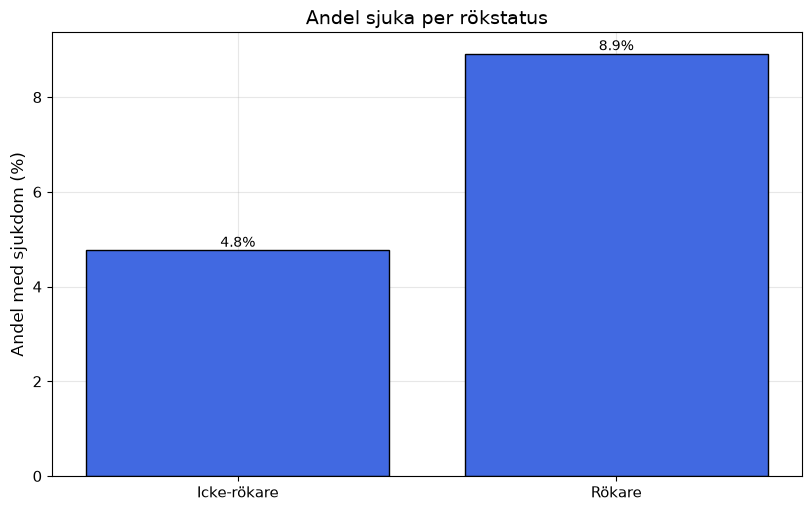

In [7]:
disease_share = df.groupby("smoker")["disease"].mean() * 100
disease_share = disease_share.reindex(["No", "Yes"])

fig, ax = plt.subplots()

bars = ax.bar(["Icke-rökare", "Rökare"], disease_share.values, edgecolor="black")
ax.bar_label(bars, fmt="%.1f%%")

ax.set_title("Andel sjuka per rökstatus")
ax.set_ylabel("Andel med sjukdom (%)")

plt.show()

**Observationer:**
- Blodtrycket är ungefär symmetriskt fördelat: kurvan är klockformad och medelvärde och median ligger nära varandra.
- Boxplotten visar några extremvärden för vikt.
- Rökare utgör ca 26,6 % av deltagarna.
- Andelen sjuka är 8,9 % bland rökare och 4,8 % bland icke-rökare, men med bara 47 sjukdomsfall är skillnaden osäker och kan inte tolkas som ett samband utan vidare analys.

### Andel sjuka och simulering

Andelen sjuka i datasetet jämförs med andelen i en simulering av 1000 personer med samma sjukdomssannolikhet.

In [8]:
disease_proportion = df["disease"].mean()
n_diseased = df["disease"].sum()

print(f"Antal sjuka i datasetet: {n_diseased} av {len(df)}")
print(f"Andel sjuka i datasetet: {disease_proportion:.4f} ({disease_proportion * 100:.2f} %)")

np.random.seed(42)
n_simulated = 1000
simulated_disease = np.random.binomial(n=1, p=disease_proportion, size=n_simulated)

simulated_proportion = simulated_disease.mean()

se_proportion = np.sqrt(disease_proportion * (1 - disease_proportion) / n_simulated)

print(f"Antal sjuka i simuleringen: {simulated_disease.sum()} av {n_simulated}")
print(f"Andel sjuka i simuleringen: {simulated_proportion:.4f} ({simulated_proportion * 100:.2f} %)")
print(f"Skillnad (simulerad - verklig): {(simulated_proportion - disease_proportion) * 100:.2f} procentenheter")
print(f"Standardfel för en andel (n = {n_simulated}): {se_proportion * 100:.1f} procentenheter")

Antal sjuka i datasetet: 47 av 800
Andel sjuka i datasetet: 0.0587 (5.88 %)
Antal sjuka i simuleringen: 56 av 1000
Andel sjuka i simuleringen: 0.0560 (5.60 %)
Skillnad (simulerad - verklig): -0.27 procentenheter
Standardfel för en andel (n = 1000): 0.7 procentenheter


Andelen sjuka är 5,88 % i datasetet och 5,60 % i simuleringen, en skillnad på ca 0,3 procentenheter. Skillnaden beror på slumpen: en andel i ett stickprov på 1000 personer varierar normalt med ca 0,7 procentenheter kring den verkliga sannolikheten.

### Konfidensintervall för medelvärdet av systolic_bp

95 %-iga konfidensintervall för medelblodtrycket beräknas med två metoder:

1. **Normalapproximation:** medelvärde ± 1,96 · standardfel, där standardfelet är s / √n. Normalfördelningens värde 1,96 används i stället för t-fördelningen eftersom stickprovet är stort.
2. **Bootstrap:** 10 000 omdragningar med återläggning. Intervallet utgörs av percentilerna 2,5 och 97,5 av omdragningarnas medelvärden.

In [9]:
# Normalapproximation

bp = df["systolic_bp"].to_numpy()
n = len(bp)

bp_mean = bp.mean()
bp_std = bp.std(ddof=1)
standard_error = bp_std / np.sqrt(n)

z_critical = 1.96
ci_normal = (bp_mean - z_critical * standard_error,
             bp_mean + z_critical * standard_error)

print(f"Medelvärde: {bp_mean:.2f} mmHg")
print(f"Standardfel: {standard_error:.3f}")
print(f"95 % CI (normalapproximation): [{ci_normal[0]:.2f}, {ci_normal[1]:.2f}]")

Medelvärde: 149.18 mmHg
Standardfel: 0.452
95 % CI (normalapproximation): [148.29, 150.07]


In [10]:
# Bootstrap

np.random.seed(42)
n_bootstrap = 10000

bootstrap_means = np.empty(n_bootstrap)
for i in range(n_bootstrap):
    resample = np.random.choice(bp, size=n, replace=True)
    bootstrap_means[i] = resample.mean()

ci_bootstrap = tuple(np.percentile(bootstrap_means, [2.5, 97.5]))

print(f"Bootstrap-standardfel: {bootstrap_means.std(ddof=1):.3f}")
print(f"95 % CI (bootstrap): [{ci_bootstrap[0]:.2f}, {ci_bootstrap[1]:.2f}]")

Bootstrap-standardfel: 0.450
95 % CI (bootstrap): [148.30, 150.07]


In [11]:
comparison = pd.DataFrame(
    {
        "Nedre gräns": [ci_normal[0], ci_bootstrap[0]],
        "Övre gräns": [ci_normal[1], ci_bootstrap[1]],
    },
    index=["Normalapproximation", "Bootstrap"],
)
comparison["Bredd"] = comparison["Övre gräns"] - comparison["Nedre gräns"]

display(comparison.round(3))

,Nedre gräns,Övre gräns,Bredd
Normalapproximation,148.292,150.065,1.773
Bootstrap,148.297,150.073,1.776


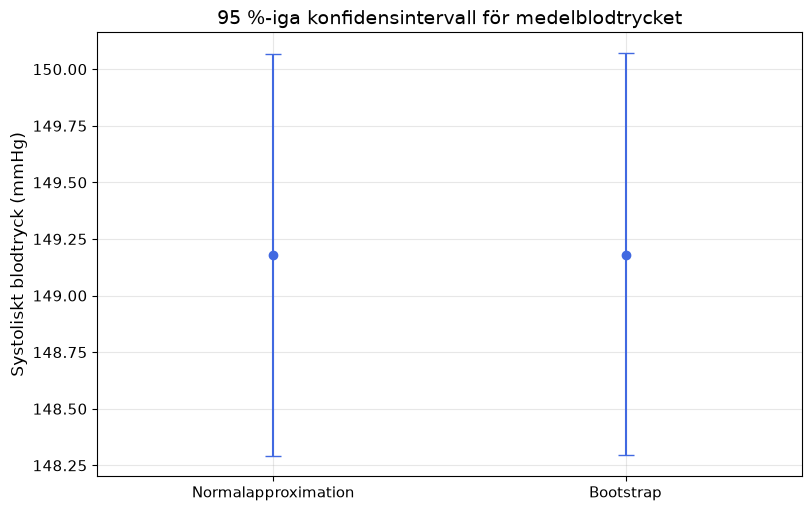

In [12]:
labels = ["Normalapproximation", "Bootstrap"]
intervals = [ci_normal, ci_bootstrap]

lower_errors = [bp_mean - lo for lo, hi in intervals]
upper_errors = [hi - bp_mean for lo, hi in intervals]

fig, ax = plt.subplots()
ax.errorbar([0, 1], [bp_mean, bp_mean], yerr=[lower_errors, upper_errors],
            fmt="o", capsize=6)

ax.set_xticks([0, 1])
ax.set_xticklabels(labels)
ax.set_xlim(-0.5, 1.5)

ax.set_title("95 %-iga konfidensintervall för medelblodtrycket")
ax.set_ylabel("Systoliskt blodtryck (mmHg)")
plt.show()

**Jämförelse av metoderna:**
Båda metoderna ger nästan samma intervall, ca 148,3–150,1 mmHg (medelvärde ca 149,2 mmHg), vilket är ett rimligt spann för det verkliga medelblodtrycket. Likheten är väntad eftersom stickprovet är stort (n = 800) och blodtrycket ungefär symmetriskt fördelat. Valet av metod påverkar därför inte slutsatsen.

### Hypotesprövning: har rökare högre medelblodtryck?

Hypoteser för `systolic_bp` enligt analysplanen:

- **H₀:** Rökare och icke-rökare har samma medelblodtryck (μ_rökare = μ_icke-rökare).
- **H₁:** Rökare har högre medelblodtryck än icke-rökare (μ_rökare > μ_icke-rökare).

Testet görs med Welchs t-test på skillnaden rökare - icke-rökare följt av ett bootstrapintervall för skillnaden och effektstorleken Cohens d.

In [13]:
group_stats = df.groupby("smoker")["systolic_bp"].agg(["count", "mean", "median", "std", "min", "max"])
display(group_stats.round(2))

smoker_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].to_numpy()
nonsmoker_bp = df.loc[df["smoker"] == "No", "systolic_bp"].to_numpy()

obs_diff = smoker_bp.mean() - nonsmoker_bp.mean()
print(f"Observerad skillnad (rökare - icke-rökare): {obs_diff:.2f} mmHg")

,count,mean,median,std,min,max
smoker,,,,,,
No,587,149.05,149.3,12.63,116.3,185.9
Yes,213,149.52,149.5,13.27,106.8,184.2


Observerad skillnad (rökare - icke-rökare): 0.47 mmHg


In [ ]:
# Manuellt Welch t-test

var_smoker = smoker_bp.var(ddof=1)
var_nonsmoker = nonsmoker_bp.var(ddof=1)
n_smoker, n_nonsmoker = len(smoker_bp), len(nonsmoker_bp)
alpha = 0.05          # signifikansnivå, används även i powersimuleringen

se_diff = np.sqrt(var_smoker / n_smoker + var_nonsmoker / n_nonsmoker)

t_manual = obs_diff / se_diff

df_num = (var_smoker / n_smoker + var_nonsmoker / n_nonsmoker) ** 2
df_den = (var_smoker**2 / ((n_smoker**2) * (n_smoker - 1))
          + var_nonsmoker**2 / ((n_nonsmoker**2) * (n_nonsmoker - 1)))
df_welch = df_num / df_den

t_critical = stats.t.ppf(1 - alpha, df_welch)

print(f"Skillnadens standardfel: {se_diff:.3f}")
print(f"t (manuell): {t_manual:.3f}")
print(f"Frihetsgrader (Welch): {df_welch:.1f}")
print(f"Kritiskt t-värde (ensidigt, α = {alpha}): {t_critical:.3f}")

Skillnadens standardfel: 1.048
t (manuell): 0.450
Frihetsgrader (Welch): 360.2
Kritiskt t-värde (ensidigt, α = 0.05): 1.649


In [15]:
# Scipy test - bekräftelse av det manuella testet

result = stats.ttest_ind(smoker_bp, nonsmoker_bp, equal_var=False, alternative="greater")

print(f"Welch t-test (ensidigt): t = {result.statistic:.3f}, p = {result.pvalue:.4f}")

Welch t-test (ensidigt): t = 0.450, p = 0.3264


In [16]:
# Konfidensintervall för skillnaden med vanlig bootstrap
np.random.seed(42)
n_bootstrap = 10_000
boot_diffs = np.empty(n_bootstrap)
for i in range(n_bootstrap):
    smoker_star = np.random.choice(smoker_bp, size=n_smoker, replace=True)
    nonsmoker_star = np.random.choice(nonsmoker_bp, size=n_nonsmoker, replace=True)
    boot_diffs[i] = smoker_star.mean() - nonsmoker_star.mean()

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
print(f"95 % CI för skillnaden (bootstrap): [{ci_low:.2f}, {ci_high:.2f}] mmHg")

# Cohen's d
pooled_std = np.sqrt(((n_smoker - 1) * var_smoker + (n_nonsmoker - 1) * var_nonsmoker)
                     / (n_smoker + n_nonsmoker - 2))
cohens_d = obs_diff / pooled_std
print(f"Cohens d: {cohens_d:.3f}")

95 % CI för skillnaden (bootstrap): [-1.63, 2.51] mmHg
Cohens d: 0.037


**Resultat:**
- **Skillnad:** Den observerade skillnaden är ca 0,47 mmHg, vilket är mindre än dess standardfel (ca 1,05 mmHg).
- **t-test:** t ≈ 0,45 ligger långt under det kritiska värdet (ca 1,65), och p ≈ 0,33 innebär att en skillnad minst lika stor är vanlig om H₀ är sann.
- **Konfidensintervall för skillnaden (bootstrap):** Ca −1,6 till +2,5 mmHg. Intervallet innehåller 0.
- **Cohens d:** Ca 0,04, en mycket liten effekt (tumregel: 0,2 liten, 0,5 medel, 0,8 stor).

**Slutsats:** H₀ kan inte förkastas vid α = 0,05, så inga belägg har hittats för att rökare har högre medelblodtryck. Det bevisar inte att ingen skillnad finns, bara att datan är förenlig med ingen skillnad. Både den observerade skillnaden (ca 0,47 mmHg) och intervallets övre gräns (ca 2,5 mmHg) ligger under den praktiskt betydelsefulla skillnaden på 5 mmHg. Eftersom studien är observationell kan resultatet inte visa orsakssamband.

### Simulering av testets styrka (power)

Testets förmåga att upptäcka en betydelsefull skillnad (power) undersöks genom att simulera normalfördelat blodtryck för rökare och icke-rökare med en känd sann skillnad. Gruppstorlekar (213 och 587) och standardavvikelser hämtas från datan. Ett ensidigt Welch-test (α = 0,05) utförs i 2000 simuleringar, och power är andelen där H₀ förkastas.

In [18]:
mean_nonsmoker = nonsmoker_bp.mean()
std_smoker = smoker_bp.std(ddof=1)
std_nonsmoker = nonsmoker_bp.std(ddof=1)

def simulate_power(true_diff, n_sim=2000):
    """Returnerar andelen simulerade dataset där det ensidiga Welch t-testet förkastar H0.

    Rökare simuleras med ett medelvärde som är true_diff mmHg högre än hos icke-rökare.
    """
    rejections = 0
    for _ in range(n_sim):
        smokers = np.random.normal(mean_nonsmoker + true_diff, std_smoker, n_smoker)
        nonsmokers = np.random.normal(mean_nonsmoker, std_nonsmoker, n_nonsmoker)
        p = stats.ttest_ind(smokers, nonsmokers, equal_var=False, alternative="greater").pvalue
        rejections += (p < alpha)
    return rejections / n_sim

In [19]:
np.random.seed(42)
true_diffs = [0, 0.5, 1, 1.5, 2, 3, 4, 5]
power_values = [simulate_power(d) for d in true_diffs]

power_table = pd.DataFrame({"Sann skillnad (mmHg)": true_diffs, "Power": power_values})
display(power_table)

,Sann skillnad (mmHg),Power
0,0.0,0.0440
1,0.5,0.1185
2,1.0,0.2135
3,1.5,0.4030
4,2.0,0.6260
5,3.0,0.8840
6,4.0,0.9820
7,5.0,0.9995


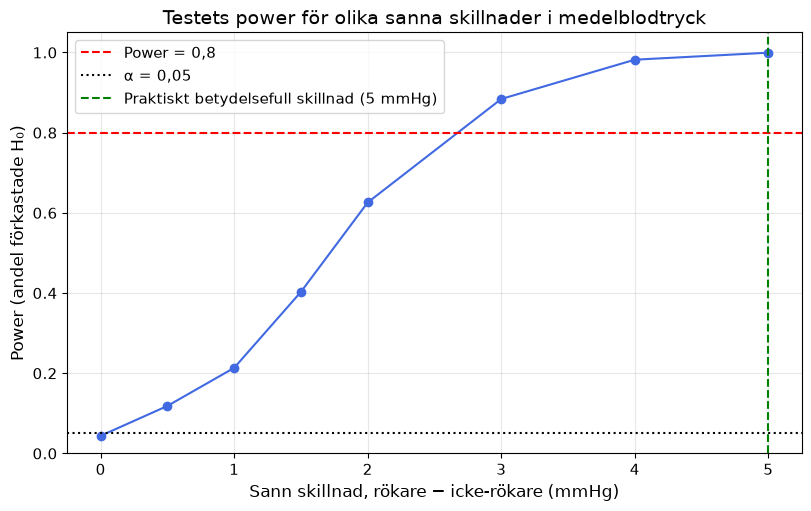

In [20]:
fig, ax = plt.subplots()
ax.plot(true_diffs, power_values, marker="o")
ax.axhline(0.8, color="red", linestyle="--", label="Power = 0,8")
ax.axhline(alpha, color="black", linestyle=":", label="α = 0,05")
ax.axvline(5, color="green", linestyle="--", label="Praktiskt betydelsefull skillnad (5 mmHg)")

ax.set_title("Testets power för olika sanna skillnader i medelblodtryck")
ax.set_xlabel("Sann skillnad, rökare − icke-rökare (mmHg)")
ax.set_ylabel("Power (andel förkastade H₀)")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()

**Observationer:**

- Vid en sann skillnad på 0 mmHg är H₀ sann, och andelen förkastade tester (ca 0,04) ligger nära α = 0,05, så andelen falska positiva är under kontroll.
- Vid 5 mmHg, den praktiskt betydelsefulla skillnaden, är power nära 100 %. Testet skulle nästan säkert upptäcka en skillnad av den storleken, vilket gör det icke-signifikanta resultatet informativt.
- För små skillnader är power låg, så testet kan inte utesluta dem, i linje med konfidensintervallet för skillnaden.

### Motivering av metodval

**Konfidensintervall med normalapproximation och bootstrap.** Normalapproximationen är enkel och bygger på centrala gränsvärdessatsen, som gör att stickprovsmedelvärdet är ungefär normalfördelat när stickprovet är stort. Bootstrap kräver inget antagande om fördelningen och är därför ett bra komplement. Percentilmetoden valdes eftersom den är enkel och transparent. (Källor: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html och https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html)

**Welchs t-test.** Grupperna har olika storlek (213 rökare och 587 icke-rökare) och något olika standardavvikelser. Welchs test antar inte lika varians och är därför ett säkrare val än det klassiska t-testet. (Källa: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)